# Chapter 5 · Brownian Bridges for ABPs — Non-linear Dynamics and Environments

Sections 5.5–5.6 (pp. 96–103), Figures 36–40.

| Figure | Page | Content |
|---|---|---|
| Figure 36 | p. 97 | Bridges in the non-linear Ballistic Brownian motion |
| Figure 37 | p. 99 | Focusing strength (widths of the endpoint distributions) |
| Figure 38 | p. 100 | Achievable particle densities |
| Figure 39 | p. 102 | Swarms scattering at a WCA wall |
| Figure 40 | p. 103 | Bridges under magnetotaxis |

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

import lambert_thesis as lt
from lambert_thesis import bridges, swarm_survey, plotting
from lambert_thesis.plotting import savefig

plotting.setup()
rng = lt.set_seed(lt.SEED)
bridge = bridges.ConditionedBridge()

## 5.5 Biasing the non-linear dynamics

Instead of injecting the conditioned noise into the paraxial solution, we now use it as the noise of the full non-linear
Ballistic Brownian motion. This subselects trajectories of the non-linear system, while marginalising the bridge
parameters still recovers the original distribution.

**Survey parameters.** 20 noise levels $\sigma$ (log-spaced from $10^3$ to $10^{-2}$), time step $5\cdot10^{-3}$,
shifts $0\dots1$ and slopes $0\dots3$ (9 values each), $10^6$ particles per swarm.
For every noise level and condition, the endpoints of the swarm are reduced to their widths, to the maximum achievable
likelihood of a Gaussian target, and — for the noise levels of Figure 36 — to 2D histograms.

*Code:* `swarm_survey.run_survey(...)`; results are stored per noise level in `results/swarm_survey_n<N>/`.
**Switch:** `FULL_RESOLUTION = True` uses $10^6$ particles per swarm (several hours of computation);
`False` uses $10^4$ particles (a few minutes), which shows all features except the noisiest curves of Figure 38.

In [2]:
SIGMAS = np.logspace(3, -2, 20)
SHIFTS = np.linspace(0, 1, 9)
SLOPES = np.linspace(0, 3, 9)
DT = 5e-3
FULL_RESOLUTION = True
N_PARTICLES = 1_000_000 if FULL_RESOLUTION else 10_000
FIG36_SIGMAS = (9, 13, 19)        # sigma = 4, 0.4, 0.01

survey = swarm_survey.run_survey(SIGMAS, N_PARTICLES, DT, SHIFTS, SLOPES, lt.SEED, hist_sigmas=FIG36_SIGMAS)
print(f"survey with {N_PARTICLES:.0e} particles per swarm loaded")

[survey] sigma 1/20 = 1e+03 ...


[survey] sigma 2/20 = 546 ...


[survey] sigma 3/20 = 298 ...


[survey] sigma 4/20 = 162 ...


[survey] sigma 5/20 = 88.6 ...


...

[survey] sigma 17/20 = 0.0616 ...


[survey] sigma 18/20 = 0.0336 ...


[survey] sigma 19/20 = 0.0183 ...


[survey] sigma 20/20 = 0.01 ...


survey with 1e+06 particles per swarm loaded


### Figure 36 (p. 97)

For each condition we draw 1000 sample trajectories (thin lines) and the density contours of the $10^6$ endpoints:
the contours wrap 99 %, 90 %, 50 % and 5 % of the probability mass ("1 %, 10 %, 50 %, 95 % density quantiles", the
histograms smoothed with a Gaussian filter of width 5 bins).

In [3]:
QUANTILE_STYLE = dict(linestyles=["--", "--", "-", "-"], linewidths=[0.5, 0.5, 1.0, 2.5])

def contours(ax, hist, cx, cy, color):
    h = gaussian_filter(hist, 5)
    ax.contour(cx, cy, h, levels=bridges.density_quantile_levels(h), colors=[color], **QUANTILE_STYLE)

def condition_panel(i_sigma, kind, values, dt, xlim, ylim, trajectories=True):
    sigma = SIGMAS[i_sigma]
    cmap = plt.get_cmap("rainbow", len(values))
    fig, ax = plt.subplots()
    for k, val in enumerate(values):
        shift, slope = (val, 0.0) if kind == "shift" else (0.0, val)
        if trajectories:
            H = bridges.ballistic_swarm(sigma, 1000, dt, rng, shift, slope, bridge, hires=True)
            ax.plot(H[:, 0].T, H[:, 1].T, c=cmap(k), lw=0.1, alpha=0.1)
        s = survey[i_sigma]
        dark = [m * c for c, m in zip(cmap(k), [0.75, 0.75, 0.75, 1])]
        contours(ax, s[f"hist_{kind}_{k}"], s[f"hist_{kind}_{k}_x"], s[f"hist_{kind}_{k}_y"],
                 dark if trajectories else cmap(k))
    ax.plot([0], [0], "+r", markersize=10, label="start")
    ax.set(xlim=xlim, ylim=ylim, xlabel="x", ylabel="y")
    ax.grid()
    cb = fig.colorbar(mpl.cm.ScalarMappable(mpl.colors.BoundaryNorm(values, cmap.N), cmap), ax=ax)
    cb.set_label(f"{kind.capitalize()} condition")
    ax.plot([], [], "k-", lw=2.5, label="5 % / 50 % of the mass")
    ax.plot([], [], "k--", lw=0.5, label="90 % / 99 % of the mass")
    fig.suptitle(f"1%, 10%, 50%, 95% Density quantiles, $\\sigma={sigma:.1g}$")
    return fig, ax

**Top row ($\sigma\approx4$).** Left: varying shift. Right: varying slope.

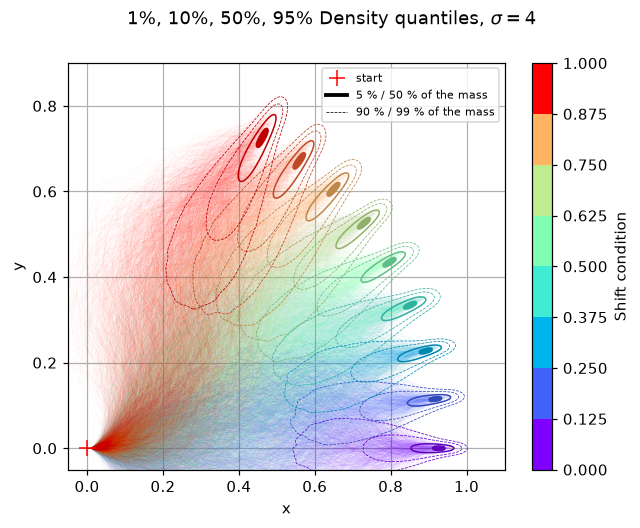

In [4]:
fig, ax = condition_panel(9, "shift", SHIFTS, 1e-2, (-.05, 1.1), (-.05, .9)); ax.legend(loc="upper right", fontsize=7)
savefig("fig36a_shift_sigma4");

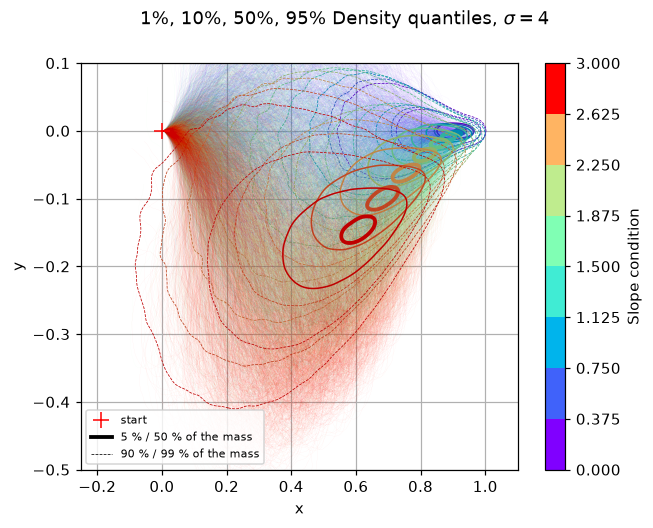

In [5]:
fig, ax = condition_panel(9, "slope", SLOPES, DT, (-.25, 1.1), (-.5, .1)); ax.legend(loc="lower left", fontsize=7)
savefig("fig36b_slope_sigma4");

**Middle row ($\sigma\approx0.4$).**

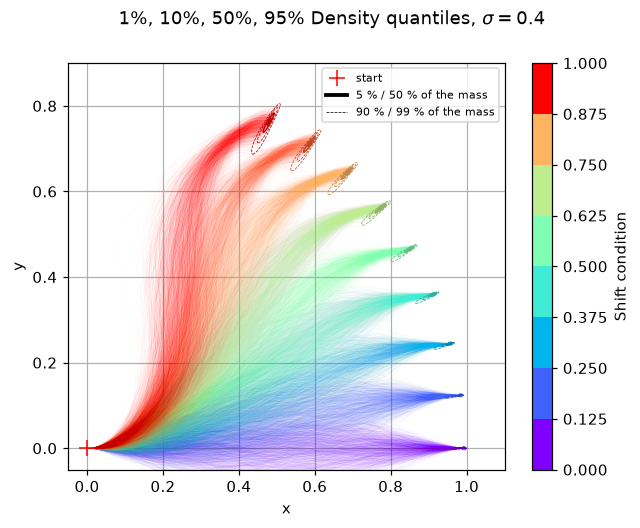

In [6]:
fig, ax = condition_panel(13, "shift", SHIFTS, 1e-2, (-.05, 1.1), (-.05, .9)); ax.legend(loc="upper right", fontsize=7)
savefig("fig36c_shift_sigma04");

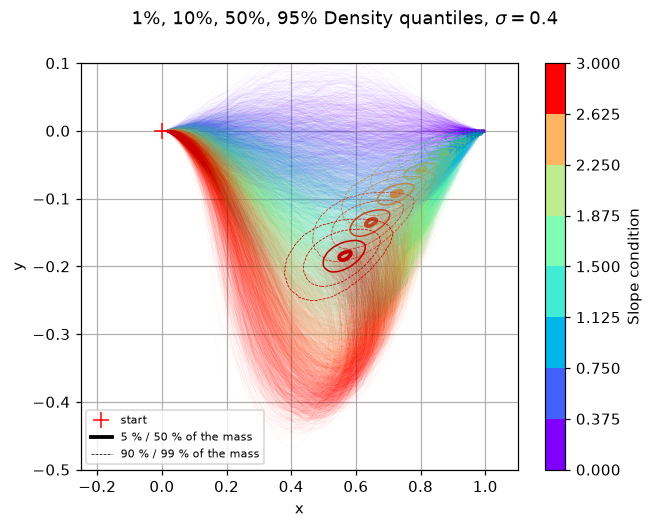

In [7]:
fig, ax = condition_panel(13, "slope", SLOPES, DT, (-.25, 1.1), (-.5, .1)); ax.legend(loc="lower left", fontsize=7)
savefig("fig36d_slope_sigma04");

**Bottom row ($\sigma=0.01$), zoomed in.** Left: the distributions are rotated so that their centre of mass lies on the
x-axis, which then shows the distance from the origin; the labels give the shift condition. Right: slope conditions,
with the straight line $y=0$ and the point $(1, 0)$ reached without noise.

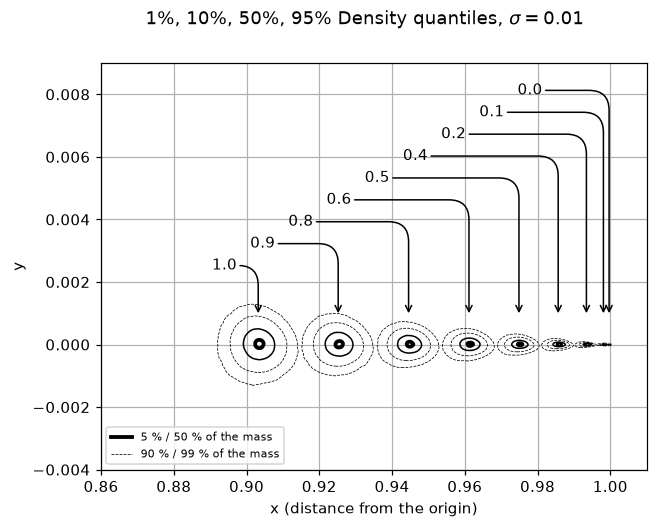

In [8]:
s = survey[19]
fig, ax = plt.subplots()
for k, shift in enumerate(SHIFTS):
    h = gaussian_filter(s[f"histrot_shift_{k}"], 5)
    cx, cy = s[f"histrot_shift_{k}_x"], s[f"histrot_shift_{k}_y"]
    ax.contour(cx, cy, h, levels=bridges.density_quantile_levels(h), colors="k", **QUANTILE_STYLE)
    P = h / h.sum()
    xc, yc = (P.sum(axis=0) * cx).sum(), (P.sum(axis=1) * cy).sum()
    ax.annotate(f"{shift:.1f}", (xc, yc + 0.001), (0.88 + 0.0105 * (len(SHIFTS) - k), 0.008 - k * 0.0007),
                arrowprops=dict(arrowstyle="->", shrinkA=0, shrinkB=0, connectionstyle="angle,angleA=0,angleB=90,rad=20"))
ax.set(xlim=(0.86, 1.01), ylim=(-.004, .009), xlabel="x (distance from the origin)", ylabel="y")
ax.grid()
ax.plot([], [], "k-", lw=2.5, label="5 % / 50 % of the mass")
ax.plot([], [], "k--", lw=0.5, label="90 % / 99 % of the mass")
ax.legend(loc="lower left", fontsize=7)
fig.suptitle(f"1%, 10%, 50%, 95% Density quantiles, $\\sigma={SIGMAS[19]:.1g}$")
savefig("fig36e_shift_sigma001");

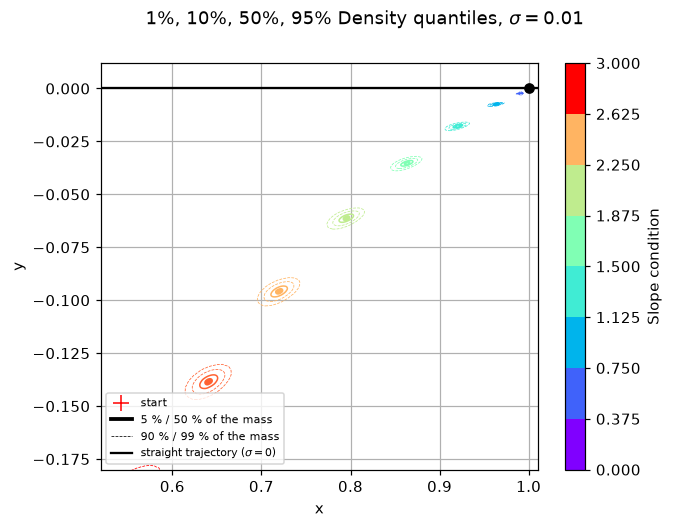

In [9]:
fig, ax = condition_panel(19, "slope", SLOPES, DT, (0.52, 1.01), (-.18, .012), trajectories=False)
ax.axhline(0, c="k", label="straight trajectory ($\\sigma=0$)")
ax.plot([1], [0], "ko")
ax.legend(loc="lower left", fontsize=7)
savefig("fig36f_slope_sigma001");

**Figure 36 (p. 97).** Sample trajectories of the full non-linear dynamics with bridge-conditioned noise; colours
indicate the bridge condition. Rows: noise level $\sigma$ (most noise at the top). Left: varying shift; right: varying slope.
The outlines wrap 1 %, 10 %, 50 % and 95 % of the probability mass of the endpoints.

The localisation after propagation is still strongly enhanced, in particular for low $\sigma$. Unlike in the paraxial
approximation, the x-location is now affected too: strongly conditioned particles travel a shorter distance. The final
angle is still controlled exactly, as the paraxial solution made no assumption about the orientation dynamics.

### Figure 37 (p. 99): focusing strength
The width (standard deviation) of the endpoint distribution, in movement direction (x) and perpendicular to it (y),
after rotating the distribution onto the x-axis.

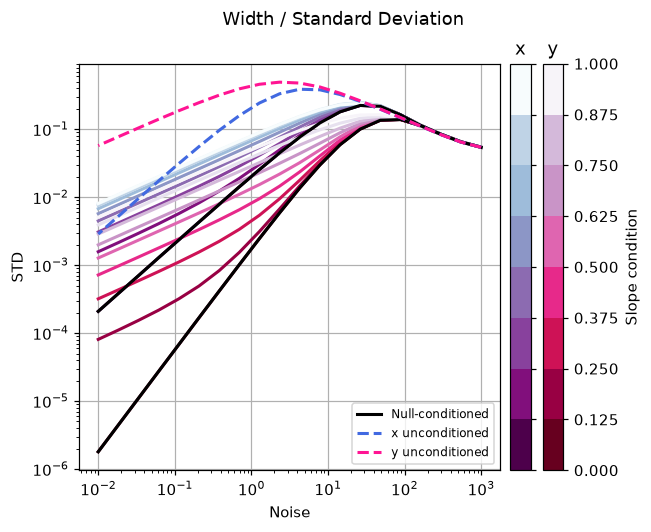

In [10]:
std = lambda key: np.array([s[key] for s in survey])            # (n_sigma, ...) arrays
std_unc, std_null, std_slope = std("std_uncond"), std("std_null"), std("std_slope")

fig, ax = plt.subplots(figsize=(6.4, 4.8))
cmapx, cmapy = plt.get_cmap("BuPu_r", len(SLOPES)), plt.get_cmap("PuRd_r", len(SLOPES))
for k in range(len(SLOPES)):
    ax.loglog(SIGMAS, std_slope[:, k, 0], color=cmapx(k), lw=2)
    ax.loglog(SIGMAS, std_slope[:, k, 1], color=cmapy(k), lw=2)
ax.loglog(SIGMAS, std_null[:, 0], "k", lw=2, label="Null-conditioned")
ax.loglog(SIGMAS, std_null[:, 1], "k", lw=2)
ax.loglog(SIGMAS, std_unc[:, 0], "--", color="royalblue", lw=2, label="x unconditioned")
ax.loglog(SIGMAS, std_unc[:, 1], "--", color="deeppink", lw=2, label="y unconditioned")
ax.set(xlabel="Noise", ylabel="STD")
ax.legend(loc="lower right", fontsize=8); ax.grid()
norm = mpl.colors.BoundaryNorm(SHIFTS, len(SLOPES))
cbb = fig.colorbar(mpl.cm.ScalarMappable(norm, cmapy), ax=ax, pad=-0.08)
cba = fig.colorbar(mpl.cm.ScalarMappable(norm, cmapx), ax=ax, pad=0.02)
cbb.ax.set_title("y"); cbb.set_label("Slope condition")
cba.ax.set_title("x"); cba.set_ticklabels([])
fig.suptitle("Width / Standard Deviation")
savefig("fig37_std_slope");

**Figure 37 (p. 99).** Dashed: unconditioned transition density (x and y component). Lower black curve: y-width of the
null-conditioned transition; non-zero slope conditions widen it (red lines). Upper black curve: width in movement
direction, which spreads into the blue curves for non-zero conditions. The bridge narrows the distribution below
$\sigma\approx100$; around $\sigma\approx1.1$, where the unconditioned spread is largest, it is about an order of
magnitude narrower.

### Figure 38 (p. 100): achievable particle densities
We optimise the location of a Gaussian target site of width $\sigma_m$ (differential evolution) to maximise the mean
target density over the swarm — the likelihood of the transition producing an observation there, i.e. the best
observation the swarm can approximate. Plotted is this maximum divided by the number of particles.

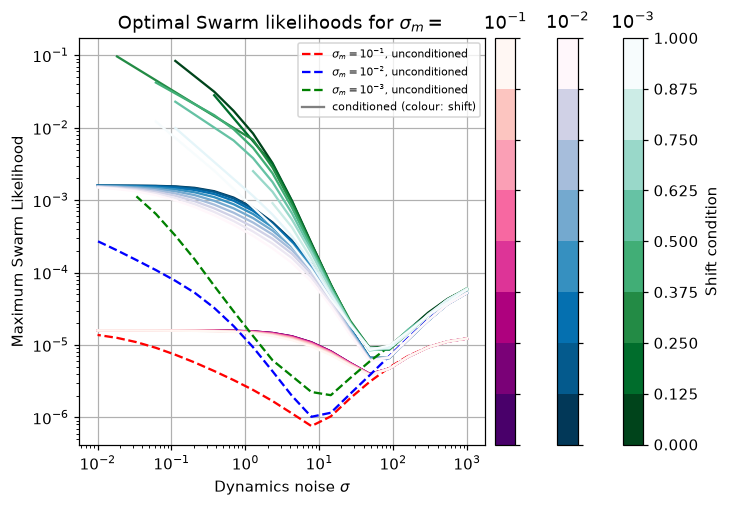

In [11]:
lik = lambda key: np.array([s[key] for s in survey])
lik_unc, lik_null, lik_ref, lik_shift = lik("lik_uncond"), lik("lik_null"), lik("lik_null_ref"), lik("lik_shift")
CUT = 1e-10
fig, ax = plt.subplots(figsize=(7.5, 4.8))
cmaps = [plt.get_cmap(c, len(SHIFTS)) for c in ("RdPu_r", "PuBu_r", "BuGn_r")]
for j, (sm, col) in enumerate(zip(swarm_survey.SIGMA_M, "rbg")):
    ok = lik_unc[:, j] > CUT
    ax.loglog(SIGMAS[ok], lik_unc[ok, j] / N_PARTICLES, "--", color=col, label=f"$\\sigma_m=10^{{{int(np.log10(sm))}}}$, unconditioned")
    for k in range(len(SHIFTS)):
        ok = lik_shift[:, k, j] > CUT
        ax.loglog(SIGMAS[ok], lik_shift[ok, k, j] / N_PARTICLES, "-", color=cmaps[j](k))
ax.plot([], [], "-", color="0.5", label="conditioned (colour: shift)")
ax.set(title="Optimal Swarm likelihoods for $\\sigma_m=$", xlabel="Dynamics noise $\\sigma$", ylabel="Maximum Swarm Likelihood")
ax.legend(fontsize=7); ax.grid()
norm = mpl.colors.BoundaryNorm(SHIFTS, len(SHIFTS))
for j, (cm_, pad) in enumerate(zip(reversed(cmaps), (-0.03, -0.02, 0.02))):
    cb = fig.colorbar(mpl.cm.ScalarMappable(norm, cm_), ax=ax, pad=pad)
    cb.ax.set_title(f"$10^{{-{3 - j}}}$")
    if j == 0:
        cb.set_label("Shift condition")
    else:
        cb.set_ticklabels([])
savefig("fig38a_likelihood_shift_vs_uncond");

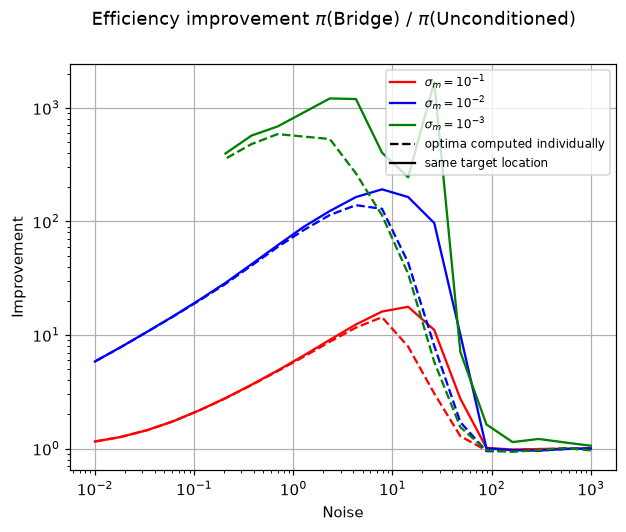

In [12]:
fig, ax = plt.subplots()
for j, (sm, col) in enumerate(zip(swarm_survey.SIGMA_M, "rbg")):
    ok = (lik_null[:, j] > CUT) & (lik_unc[:, j] > CUT)
    ax.loglog(SIGMAS[ok], lik_null[ok, j] / lik_unc[ok, j], "--", color=col)
    ok = (lik_null[:, j] > CUT) & (lik_ref[:, j] > CUT)
    ax.loglog(SIGMAS[ok], lik_null[ok, j] / lik_ref[ok, j], color=col, label=f"$\\sigma_m=10^{{{int(np.log10(sm))}}}$")
ax.plot([], [], "k--", label="optima computed individually")
ax.plot([], [], "k-", label="same target location")
ax.set(xlabel="Noise", ylabel="Improvement")
ax.legend(fontsize=8); ax.grid()
fig.suptitle("Efficiency improvement $\\pi$(Bridge) / $\\pi$(Unconditioned)")
savefig("fig38b_likelihood_improvement");

**Figure 38 (p. 100).** Left: maximum achievable likelihood for the unconditioned (dashed) and conditioned (continuous)
transition densities. Very low noise straightens the trajectories, very high noise curls them into small blobs — both focus
the swarm; the bridge additionally focuses at intermediate values. Right: ratio of the likelihoods with and without
conditioning (null bridge). Dashed: the best achievable values computed individually; continuous: same target location,
optimised for the bridge. The largest improvement occurs for $\sigma\approx1$, where we expect the inference to profit most.

## 5.6 Interactions with environments

### Wall scatterings
Particles start at $(-0.5, 0.5)$ with orientation $\pi/4$ and speed $v=1.2$ and hit a repulsive wall at $x=0$, modelled by
the force $F=(10x)^6$ for $x>0$ and the torque $\alpha F\sin\phi$ that turns the particle away from the wall
(1000 particles, $\Delta t=5\cdot10^{-4}$, $T=2$). Green: unconditioned; red: null bridge.

*Code:* `bridges.ballistic_swarm(..., X0, T, v, force, torque, hires=True)` with the wall as `force`/`torque` callables.
The bridge conditions are given in noise units (`noise_units=True`), scaled by $N/(v\sqrt{\sigma\,\Delta t})$.

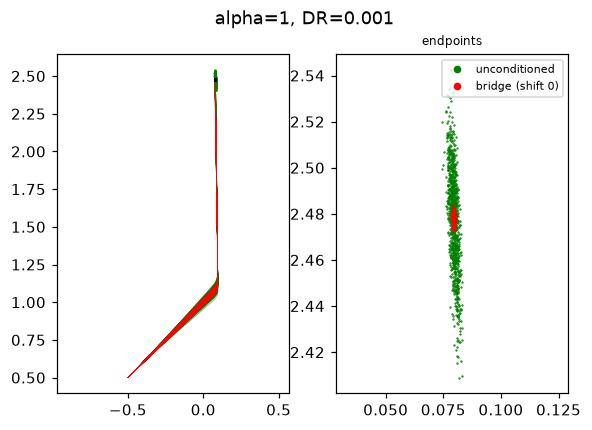

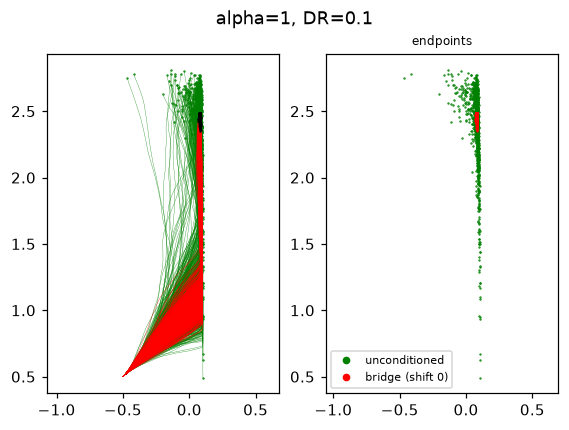

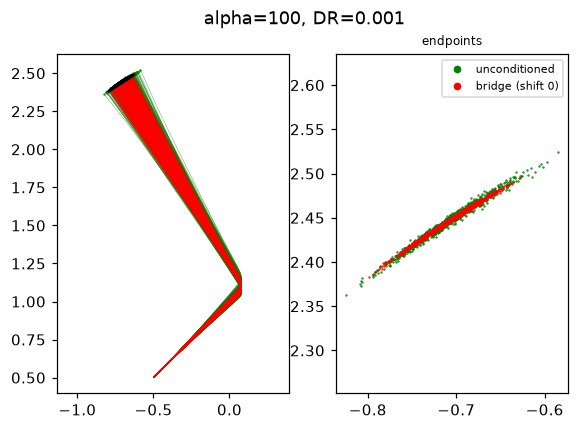

In [13]:
wall_force = lambda X: (-(10 * X[:, 0]) ** 6 * (X[:, 0] > 0), 0.0)

def wall_torque(alpha):
    return lambda X, t: alpha * (10 * X[:, 0]) ** 6 * (X[:, 0] > 0) * np.sin(X[:, 2])

def wall_swarm(alpha, sigma, shift=None):
    kw = dict(X0=(-0.5, 0.5, np.pi / 4), T=2.0, v=1.2, force=wall_force, torque=wall_torque(alpha), hires=True)
    if shift is None:
        return bridges.ballistic_swarm(sigma, 1000, 5e-4, rng, **kw)
    n_steps = int(2.0 / 5e-4 + 1)
    factor = n_steps / (np.sqrt(sigma * 2.0 / n_steps) * 1.2)
    return bridges.ballistic_swarm(sigma, 1000, 5e-4, rng, shift * factor, 0.0, bridge, noise_units=True, **kw)

def scatter_panel(H_a, H_b, col_a, col_b, ends_b, label_a, label_b, title):
    fig, (ax, axin) = plt.subplots(ncols=2, figsize=(6, 4))
    ax.plot(H_a[:, 0].T, H_a[:, 1].T, color=col_a, lw=0.2)
    ax.plot(H_a[:, 0, -1], H_a[:, 1, -1], ".", color=col_a, ms=1)
    ax.plot(H_b[:, 0].T, H_b[:, 1].T, color=col_b, lw=0.2)
    ax.plot(H_b[:, 0, -1], H_b[:, 1, -1], ".", color=ends_b, ms=1)
    ax.axis("equal")
    axin.plot(H_a[:, 0, -1], H_a[:, 1, -1], ".", color=col_a, ms=1, label=label_a)
    axin.plot(H_b[:, 0, -1], H_b[:, 1, -1], ".", color=col_b, ms=1, label=label_b)
    axin.axis("equal"); axin.set_title("endpoints", fontsize=8)
    axin.legend(fontsize=7, markerscale=8)
    fig.suptitle(title)
    return fig

for n_, (alpha, sigma) in enumerate([(1, 1e-3), (1, 0.1), (100, 1e-3)], start=1):
    scatter_panel(wall_swarm(alpha, sigma), wall_swarm(alpha, sigma, shift=0.0), "g", "r", "k",
                  "unconditioned", "bridge (shift 0)", f"alpha={alpha}, DR={sigma}")
    savefig(f"fig39_{n_}_wall_alpha{alpha}_sigma{sigma}")

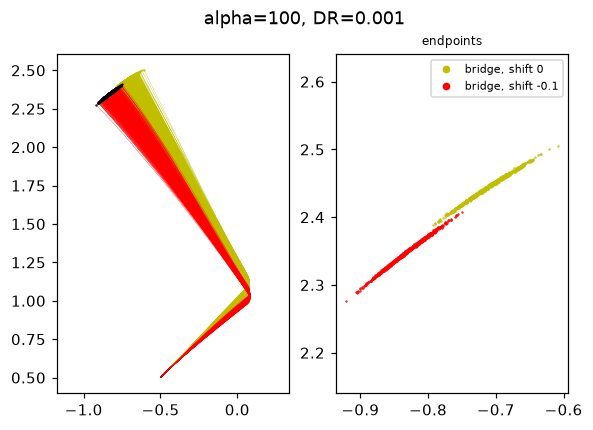

In [14]:
scatter_panel(wall_swarm(100, 1e-3, shift=0.0), wall_swarm(100, 1e-3, shift=-0.1), "y", "r", "k",
              "bridge, shift 0", "bridge, shift -0.1", "alpha=100, DR=0.001")
savefig("fig39_4_wall_two_bridges");

**Figure 39 (p. 102).** Swarms colliding with a WCA wall under the torque scaling $\alpha$. Top row (low torque): the
orientation adapts slowly, the particles slide along the wall and the conditioned swarm stays close together. Bottom row
(high torque): the particles are reflected; the conditioned swarm loses its coherence. Bottom right: two bridge conditions
(red, yellow) both spread, but keep their difference in shift.

### Magnetotaxis
The particles carry a magnetic dipole and turn towards the field direction $\phi_B$ with the torque $B\sin(\phi_B-\phi)$
(100 particles, $v=1.2$, $\Delta t=5\cdot10^{-3}$, $T=1$, start at $(-0.5,0.5)$). Top row: field pointing upwards
($\phi_B=\pi/2$), particles start heading in $+x$. Bottom row: the field oscillates back and forth by 45° around the
y-axis, $\phi_B(t)=\pi/2+\frac\pi2\cos(20\,t)$, particles start heading upwards.

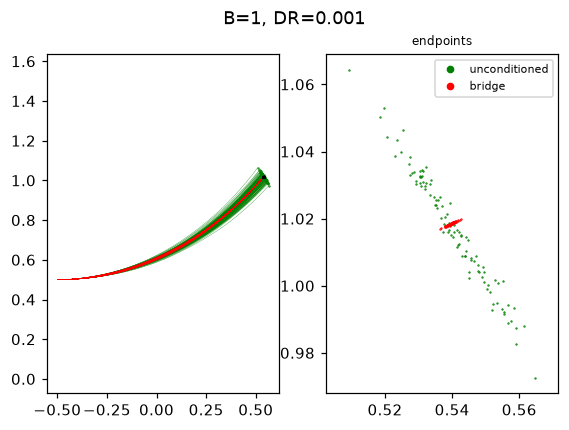

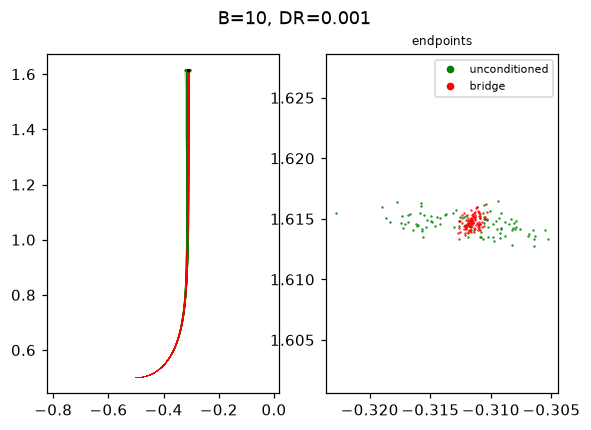

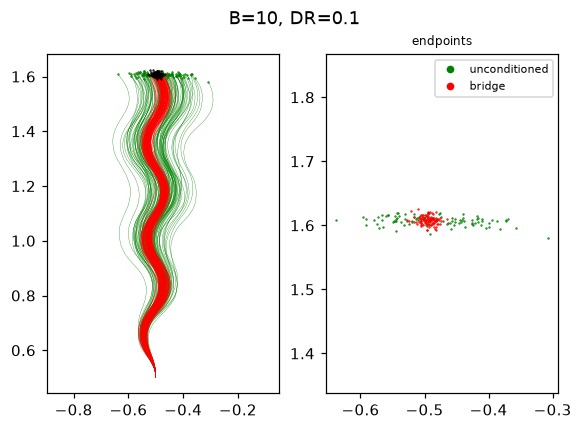

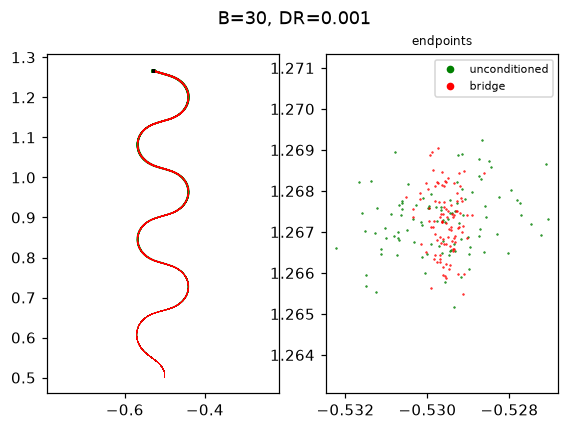

In [15]:
def field_torque(B, oscillating):
    phi_B = (lambda t: np.pi / 2 + np.pi / 2 * np.cos(20 * t)) if oscillating else (lambda t: np.pi / 2)
    return lambda X, t: B * np.sin(phi_B(t) - X[:, 2])

def field_swarm(B, sigma, oscillating, bridged):
    kw = dict(X0=(-0.5, 0.5, np.pi / 2 if oscillating else 0.0), T=1.0, v=1.2,
              torque=field_torque(B, oscillating), hires=True)
    if bridged:
        return bridges.ballistic_swarm(sigma, 100, 5e-3, rng, 0.0, 0.0, bridge, noise_units=True, **kw)
    return bridges.ballistic_swarm(sigma, 100, 5e-3, rng, **kw)

for n_, (B, sigma, osc) in enumerate([(1, 1e-3, False), (10, 1e-3, False), (10, 0.1, True), (30, 1e-3, True)], start=5):
    scatter_panel(field_swarm(B, sigma, osc, False), field_swarm(B, sigma, osc, True), "g", "r", "k",
                  "unconditioned", "bridge", f"B={B}, DR={sigma}")
    savefig(f"fig40_{n_}_field_B{B}_sigma{sigma}")

**Figure 40 (p. 103).** Unconditioned (green) and conditioned (red) noise under magnetotaxis: field pointing upwards
(top row) or oscillating by 45° around the y-axis (bottom row). The field focuses the swarm by itself, turning the diffusive
long-term motion into effectively ballistic motion; the unconditioned swarm shrinks to sizes comparable to the conditioned
one, which loses its advantage.